# 09. Мастер-датасет вакансий 2024–2026

Одна таблица по **единым правилам** для всех источников, собранная заново из исходных файлов:

| Источник | Исходный файл | Период |
|---|---|---|
| hh.kg, lalafo.kg (School of Data Kyrgyzstan) | `data/raw/vacancy.xlsx` | снимок февраль–март 2024 |
| Telegram @codifynews, @kgworkzone | `data/raw/telegram_posts.jsonl` | январь 2024 – октябрь 2026 |

**Принципы:**
1. **Ничего не придумывается.** Если опыт, город, образование не указаны в объявлении, ячейка пустая.
   Если значение получено правилом, колонка `*_basis` говорит, каким.
2. **Даты точные**, во времени Бишкека (UTC+6).
3. **Сохраняется каждое слово объявления:** полный текст в `ad_text`, всё, что не вынесено в колонки, в `additional_info`.
4. **Строки удаляются только по записанной причине** (журнал ниже).

Правила записаны в одном месте: `src/dataset.py`. Результат:
`data/processed/vacancies_2024_2026_master.csv.gz` (для кода, читается `pd.read_csv` напрямую) и
`data/processed/vacancies_2024_2026_master.xlsx` (для чтения; листы: вакансии, словарь, правила, журнал, сводка).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore", category=UserWarning)
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import dataset as ds

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
pd.set_option("display.max_colwidth", 90)

d, log, acc = ds.build("../data/raw/vacancy.xlsx", "../data/raw/telegram_posts.jsonl")
print(f"Итог: {len(d):,} вакансий, {d.shape[1]} колонок".replace(",", " "))
print(f"Классификатор профессий для Telegram: точность на отложенных вакансиях hh/lalafo: "
      f"сфера {acc['sector']:.0%}, профессия {acc['profession']:.0%}")
log

hh/lalafo: 13349 строк в файле, 13347 после удаления не-вакансий


Telegram: 65491 постов → 60781 вакансий codifynews, 3844 вакансий kgworkzone


Итог: 53 916 вакансий  44 колонок
Классификатор профессий для Telegram: точность на отложенных вакансиях hh/lalafo: сфера 82%, профессия 79%


,шаг,почему,строк
0,hh/lalafo: удалены резюме и объявления об услугах,не вакансии,2
1,hh/lalafo: валюта не указана → KGS,объявления lalafo из Кыргызстана,5
2,Профессия «Менеджер по продажам» перенесена в сферу «Продажи»,ошибка справочника источника,575
3,Telegram: посты других каналов,DevKG: 20 постов в другом формате,20
4,codifynews: посты не по шаблону,"реклама, анонсы, подкасты",319
5,kgworkzone: посты не про вакансии,"мемы, советы, анонсы канала",551
6,kgworkzone: заметки о канале и посты без заголовка,заголовок про канал («этот канал…») или не найден,41
7,kgworkzone: посты с несколькими вакансиями разделены,одна строка на вакансию,68
8,Вне периода 2024–2026,lalafo: объявление не обновлялось с 2023 года,496
9,Повторные публикации объединены,"тот же источник, заголовок, работодатель и зарплата в течение 30 дней; оставлена перва...",23560


## 1. Правила

In [2]:
pd.DataFrame(ds.RULES, columns=["тема", "правило"]).style.hide(axis="index")

тема,правило
Даты,"Все даты переведены в время Бишкека (UTC+6). Дата для анализа (reference_date): hh и Telegram: дата публикации; lalafo: дата последнего обновления (объявления поднимают, и в снимке 2024 года были живые объявления, впервые опубликованные в 2017–2023)."
Период,"В таблицу входят вакансии с reference_date с 1 января 2024. Объявления lalafo, не обновлявшиеся с 2023, удалены."
Повторы,"Одинаковые источник, заголовок, работодатель и строка зарплаты (для lalafo и kgworkzone также начало текста) в пределах 30 дней = одна вакансия: остаётся первая публикация, число публикаций в times_published. Повтор через 30+ дней считается новым набором."
Не вакансии,lalafo: резюме («ищу работу») и услуги/аренда удалены. Telegram: посты codifynews не по шаблону и посты kgworkzone без признаков вакансии удалены.
Опыт,"Только явно указанный: поле сайта (hh, lalafo), поле «Дополнительно» (codifynews), фраза в тексте (kgworkzone). «С опытом / опыт обязателен» без срока = «требуется, срок не указан». Уровень Middle/Senior НЕ переводится в годы. Если не указан, пусто."
Город,Только явно указанный. Название канала («Работа Бишкек») городом не считается.
Профессия,"hh и lalafo: из источника (с исправлением ошибки справочника для менеджеров по продажам). Telegram: классификатор по заголовку (TF-IDF + LinearSVC), обученный на hh и lalafo."
Зарплата,"Диапазон: середина; одна граница: она сама. Валюта не указана (lalafo): KGS. USD и EUR по курсу НБКР своего года (2024: 14.03.2024; 2025: 02.07.2025; 2026: 30.06.2026). RUB и KZT не пересчитываются: строка остаётся, зарплата помечена."
Период оплаты,"Сначала явные слова («в час», «за смену/в день», «в месяц», «в неделю»); «в месяц» важнее «выплаты раз в неделю». Без слов: 500–5 000 сом считаются дневной ставкой, остальное месячной. Пересчёт: час × 208, день × 26, неделя × 4,33."
Неправдоподобные зарплаты,"Меньше 10 тыс. или больше 600 тыс. сом в месяц после пересчёта: зарплата не используется, вакансия остаётся со статусом."


## 2. Даты

- Все даты переведены из UTC во **время Бишкека**. Раньше хранились в UTC, и вакансия, опубликованная в 18:00–24:00 UTC,
  попадала на предыдущий день.
- **lalafo:** объявления поднимают, поэтому в снимке февраля–марта 2024 были живые объявления, впервые опубликованные
  в 2017–2023. Датой для анализа считается **последнее обновление**. Раньше такие объявления удалялись целиком.
- **Повторы:** одна вакансия, опубликованная несколько раз в течение 30 дней, это одна строка с датой первой публикации,
  числом публикаций `times_published` и датой последней `last_published_at`.

In [3]:
display(d.groupby("source").agg(вакансий=("vacancy_id", "size"), с=("reference_date", "min"), по=("reference_date", "max"),
                                основа_даты=("date_basis", "first")))
la = d[d["source"] == "lalafo.kg"]
print("lalafo: год первой публикации объявлений, живых в 2024:")
display(la["published_at"].dt.year.value_counts().sort_index().to_frame("объявлений").T)
print("Сколько раз вакансия была опубликована (повторы за 30 дней объединены):")
d["times_published"].clip(upper=6).value_counts().sort_index().rename(index={6: "6+"}).to_frame("вакансий").T

,вакансий,с,по,основа_даты
source,,,,
Telegram @codifynews,38169,2024-01-01 17:01:00,2026-10-28 15:41:10,публикация в канале
Telegram @kgworkzone,3377,2025-11-29 16:22:50,2026-10-28 17:33:12,публикация в канале
hh.kg,3442,2024-02-29 09:22:45,2024-03-30 19:38:31,публикация
lalafo.kg,8928,2024-01-02 21:50:33,2024-03-30 03:31:45,последнее обновление объявления


lalafo: год первой публикации объявлений, живых в 2024:


published_at,2017,2018,2019,2020,2021,2022,2023,2024
объявлений,10,18,49,95,273,550,1928,6005


Сколько раз вакансия была опубликована (повторы за 30 дней объединены):


times_published,1,2,3,4,5,6+
вакансий,47597,2913,1087,577,378,1364


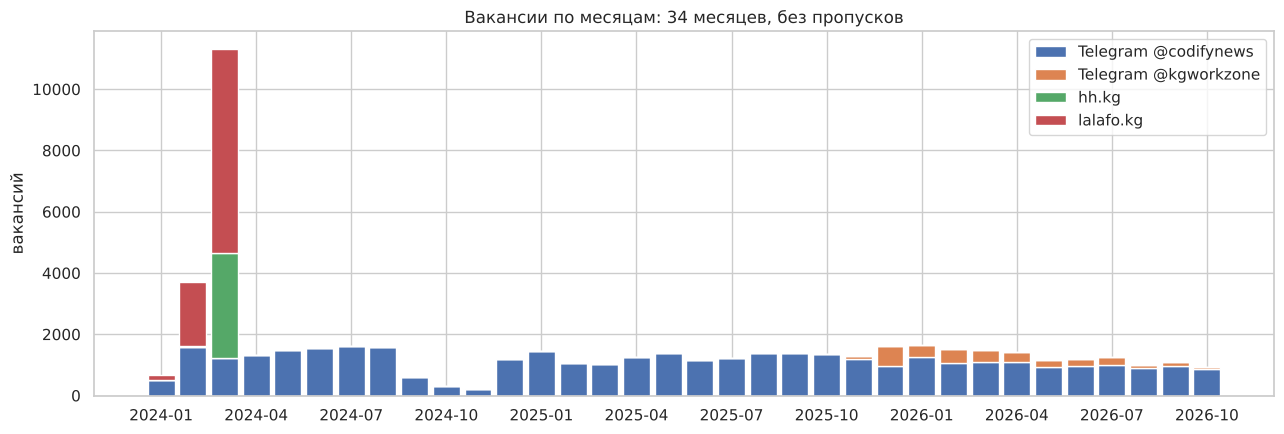

In [4]:
m = d.groupby([d["reference_date"].dt.strftime("%Y-%m"), "source"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(13, 4.5))
bottom = np.zeros(len(m))
for src in m.columns:
    ax.bar(range(len(m)), m[src].values, bottom=bottom, label=src, width=0.85); bottom += m[src].values
ax.set_xticks(range(0, len(m), 3)); ax.set_xticklabels(m.index[::3])
ax.set_title(f"Вакансии по месяцам: {len(m)} месяцев, без пропусков"); ax.set_ylabel("вакансий"); ax.legend(title="")
plt.tight_layout(); plt.savefig(FIG + "09_months.png", dpi=150); plt.show()

## 3. Опыт: только указанный

Источник опыта для каждой строки записан в `experience_basis`. Если опыт не указан, ячейка **пустая**
(в файле для моделей раньше подставлялся 1 год). Уровень из поля «Тип» codifynews (Middle, Senior)
хранится отдельно в `level_in_post` и в годы не переводится.

In [5]:
e = pd.crosstab(d["source"], d["experience_required"].fillna("не указан"))
e = e[[c for c in ["без опыта", "1–3 года", "3–6 лет", "6+ лет", "требуется, срок не указан", "не указан"] if c in e.columns]]
display(e)
pd.crosstab(d["source"], d["experience_basis"].fillna("не указан"))

experience_required,без опыта,1–3 года,3–6 лет,6+ лет,"требуется, срок не указан",не указан
source,,,,,,
Telegram @codifynews,3211,13310,3779,388,0,17481
Telegram @kgworkzone,342,385,115,19,917,1599
hh.kg,759,1943,653,87,0,0
lalafo.kg,4093,3216,925,694,0,0


experience_basis,не указан,поле «Дополнительно»,поле сайта,текст объявления
source,,,,
Telegram @codifynews,17481,20688,0,0
Telegram @kgworkzone,1599,0,0,1778
hh.kg,0,0,3442,0
lalafo.kg,0,0,8928,0


## 4. Зарплата

In [6]:
display(pd.crosstab(d["source"], d["salary_status"]))
pd.crosstab(d["source"], d["pay_period_basis"].fillna("зарплаты нет"))

salary_status,"в рублях или тенге, не пересчитана",неоплачиваемая,неправдоподобная (меньше 10 тыс. или больше 600 тыс.),скрыта,указана
source,,,,,
Telegram @codifynews,3129,292,154,14941,19653
Telegram @kgworkzone,5,0,14,1471,1887
hh.kg,155,0,3,1409,1875
lalafo.kg,0,0,372,5031,3525


pay_period_basis,зарплаты нет,"не указано, считается месячной",по сумме: 500–5 000 сом в месяц неправдоподобно,указано в тексте
source,,,,
Telegram @codifynews,18362,12865,148,6794
Telegram @kgworkzone,1476,872,203,826
hh.kg,1564,1870,6,2
lalafo.kg,5031,2610,829,458


Как строка зарплаты превращается в число (случайные примеры по каждому правилу периода):

In [7]:
ex = (d[d["salary_text"].notna() & d["pay_period_basis"].notna()].sample(frac=1, random_state=1)
      .groupby(["pay_period_basis", "pay_period"]).head(2).sort_values(["pay_period_basis", "pay_period"]))
ex[["source", "salary_text", "salary_from", "salary_to", "currency", "pay_period", "pay_period_basis", "salary_month_kgs", "salary_status"]]

,source,salary_text,salary_from,salary_to,currency,pay_period,pay_period_basis,salary_month_kgs,salary_status
22106,Telegram @codifynews,70000 - 125000 KGS,70000.0,125000.0,KGS,месяц,"не указано, считается месячной",97500.0,указана
32312,Telegram @codifynews,от 30000 KGS,30000.0,NaN,KGS,месяц,"не указано, считается месячной",30000.0,указана
40007,Telegram @kgworkzone,Оплата: • от 2000 сом + %,2000.0,NaN,KGS,день,по сумме: 500–5 000 сом в месяц неправдоподобно,52000.0,указана
42953,Telegram @kgworkzone,• Зарплата: 2000–2500 сом + дорога,2000.0,2500.0,KGS,день,по сумме: 500–5 000 сом в месяц неправдоподобно,58500.0,указана
40630,Telegram @kgworkzone,💰 Заработная плата: ➡️ от 3000 до 3500 сом за смену,3000.0,3500.0,KGS,день,указано в тексте,84500.0,указана
46097,Telegram @kgworkzone,💰 Оплата: 1500–1800 сом в день,1500.0,1800.0,KGS,день,указано в тексте,42900.0,указана
45660,Telegram @kgworkzone,💰 Зарплата: от 40 000 сом/мес,40000.0,NaN,KGS,месяц,указано в тексте,40000.0,указана
597,Telegram @codifynews,От 15000 KGS в месяц,15000.0,NaN,KGS,месяц,указано в тексте,15000.0,указана
48929,Telegram @kgworkzone,💰 Зарплата: • 10 000 – 12 000 сом в неделю,10000.0,12000.0,KGS,неделя,указано в тексте,47630.0,указана
49457,Telegram @kgworkzone,💰 Айлык: жумасына 12 500 сом,12500.0,NaN,KGS,неделя,указано в тексте,54120.0,указана


## 5. Город и прочие поля: заполненность

In [8]:
filled = d[["employer", "city_group", "experience_required", "work_format", "education_required", "gender_required",
            "schedule", "salary_month_kgs", "additional_info"]].notna().groupby(d["source"]).mean()
filled.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

,employer,city_group,experience_required,work_format,education_required,gender_required,schedule,salary_month_kgs,additional_info
source,,,,,,,,,
Telegram @codifynews,100%,54%,54%,96%,0%,0%,0%,51%,100%
Telegram @kgworkzone,0%,37%,53%,1%,1%,17%,52%,56%,99%
hh.kg,100%,100%,100%,1%,5%,0%,0%,54%,99%
lalafo.kg,4%,100%,100%,1%,1%,11%,13%,39%,98%


## 6. Полный текст и дополнительная информация

In [9]:
for r in d[d["source"] == "Telegram @kgworkzone"].sample(2, random_state=7).itertuples():
    print(f"=== {r.job_title} | {r.salary_text} → {r.salary_month_kgs} сом/мес | опыт: {r.experience_required} | город: {r.locality}")
    print("additional_info:\n" + str(r.additional_info)[:600] + "\n")

=== Графический дизайнер-печатник | 💰 Зарплата: 50 000 – 65 000 сом → 57500.0 сом/мес | опыт: 1–3 года | город: Бишкек
additional_info:
📍 Адрес: г. Бишкек, ул. Якова Логвиненко, 8/2
📅 График: 6/1
⏰ Время работы: Пн–Пт с 10:00 до 19:00, Сб с 10:00 до 15:00
📋 Обязанности:
• Подготовка файлов к печати
• Печать полиграфической продукции
• Работа с лазерными печатными машинами Konica Minolta
🎁 Мы предлагаем:
• Стабильную заработную плату
• Выплаты 2 раза в месяц
• Работу в офисе
• Выходной — воскресенье
✅ Требования:
• Опыт работы от 1 года
• Владение Adobe Photoshop, CorelDRAW, Adobe Illustrator, Adobe InDesign
• Умение работать с лазерными машинами Konica Minolta
• Навыки подготовки файлов к печати
📲: [телефон]| Написать 👈
Наш ка

=== ПОВАРА В РЕСТОРАН ZERNO | nan → nan сом/мес | опыт: nan | город: nan
additional_info:
📌 Условия и требования:
• Опытный пекарь (парни): 2000 сом
• Пекарни (девушки): 1500 сом, обучение возможно
• График работы: 4/2, с 11:00 до 23:00
• Адрес: ул. Турусбекова 

## 7. Сравнение с первой версией (ноутбук 07)

Первая версия объединённой таблицы (ноутбук 07, файл `vacancies_2024_2026.csv` удалён после перехода на мастер-датасет):

| Источник | Вакансий: первая версия | Вакансий: мастер | С зарплатой: первая версия | С зарплатой: мастер | Опыт подставлен / не указан |
|---|---|---|---|---|---|
| Telegram @codifynews | 28 964 | 38 169 | 16 661 | 19 653 | 25% подставлено → 46% пусто |
| Telegram @kgworkzone | 3 046 | 3 377 | 1 681 | 1 887 | 47% подставлено → 47% пусто |
| hh.kg | 3 437 | 3 442 | 2 028 | 1 875 | поле сайта в обеих версиях |
| lalafo.kg | 5 855 | 8 928 | 2 340 | 3 525 | поле сайта в обеих версиях |

**Почему числа отличаются:**
- **lalafo** больше: объявления, впервые опубликованные до 2024, но обновлённые в 2024, теперь входят.
- **codifynews** больше: раньше повтором считалась та же вакансия в любой момент; теперь только в течение 30 дней,
  а повтор через месяц и больше считается новым набором (медианный промежуток у таких повторов около 70 дней).
  Вакансии в рублях и тенге теперь остаются со статусом, а не удаляются.
- **hh** с зарплатой меньше: 155 вакансий в рублях больше не пересчитываются в сомы.
- **kgworkzone:** зарплата найдена чаще (строка «💰 Оплата:» с суммой на следующей строке), заметки о канале удалены.
- **Опыт:** в первой версии неуказанный опыт заменялся на 1 год, а уровень Middle/Senior переводился в годы;
  теперь такие ячейки пустые.

## 8. Проверки целостности

In [10]:
checks = {
    "id уникальны": d["vacancy_id"].is_unique,
    "все даты в 2024–2026": d["reference_date"].between("2024-01-01", "2026-12-31").all(),
    "зарплата заполнена только при статусе «указана»": (d["salary_month_kgs"].notna() == (d["salary_status"] == "указана")).all(),
    "зарплаты в пределах 10–600 тыс.": d["salary_month_kgs"].dropna().between(10_000, 600_000).all(),
    "у каждого значения опыта есть источник": (d["experience_required"].notna() == d["experience_basis"].notna()).all(),
    "годы опыта только при указанном сроке": (d["experience_min_years"].isna() | d["experience_basis"].notna()).all(),
    "нет номеров телефонов в текстах": ~pd.concat([d["ad_text"], d["additional_info"]]).fillna("").str.contains(r"(?<!\d)\d{9,12}(?!\d)").any(),
    "у каждой вакансии есть заголовок": d["job_title"].notna().all(),
}
for k, v in checks.items():
    print(("OK   " if v else "FAIL ") + k)
assert all(checks.values())

OK   id уникальны
OK   все даты в 2024–2026
OK   зарплата заполнена только при статусе «указана»
OK   зарплаты в пределах 10–600 тыс.
OK   у каждого значения опыта есть источник
OK   годы опыта только при указанном сроке
OK   нет номеров телефонов в текстах
OK   у каждой вакансии есть заголовок


## 9. Словарь данных и сохранение

In [11]:
dictionary = pd.DataFrame(ds.DICTIONARY, columns=["колонка", "описание"])
assert list(dictionary["колонка"]) == list(d.columns)
summary = d.groupby(["source", "year"]).agg(вакансий=("vacancy_id", "size"), с_зарплатой=("salary_month_kgs", "count"),
                                            медианная_зарплата=("salary_month_kgs", "median")).reset_index()
d.to_csv("../data/processed/vacancies_2024_2026_master.csv.gz", index=False)    # сжатый: полный текст объявлений занимает ~60 МБ

xl = d.drop(columns=["ad_text"]).copy()
xl["additional_info"] = xl["additional_info"].str.slice(0, 1000)
for c in ["reference_date", "published_at", "last_updated_at", "last_published_at"]:
    xl[c] = xl[c].dt.strftime("%Y-%m-%d %H:%M")
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
sheets = {"вакансии": xl, "словарь": dictionary, "правила": pd.DataFrame(ds.RULES, columns=["тема", "правило"]),
          "журнал": log, "сводка": summary}
with pd.ExcelWriter("../data/processed/vacancies_2024_2026_master.xlsx", engine="openpyxl") as w:
    for name, frame in sheets.items():
        frame.to_excel(w, sheet_name=name, index=False)
        ws = w.sheets[name]
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        for i, col in enumerate(frame.columns, 1):
            ws.cell(1, i).font = Font(bold=True, color="FFFFFF")
            ws.cell(1, i).fill = PatternFill("solid", fgColor="3B7DD8")
            width = frame[col].astype(str).str.len().quantile(0.9) if len(frame) else 10
            ws.column_dimensions[get_column_letter(i)].width = min(max(len(str(col)) + 2, width + 2), 70 if name != "вакансии" else 40)
        if name in ("словарь", "правила", "журнал"):
            for row in ws.iter_rows(min_row=2):
                for cell in row:
                    cell.alignment = Alignment(wrap_text=True, vertical="top")
print("Сохранено: vacancies_2024_2026_master.csv.gz и .xlsx")
summary.style.format({"медианная_зарплата": "{:,.0f}"}).hide(axis="index")

Сохранено: vacancies_2024_2026_master.csv.gz и .xlsx


source,year,вакансий,с_зарплатой,медианная_зарплата
Telegram @codifynews,2024,13235,6082,"60,000"
Telegram @codifynews,2025,14849,7572,"65,000"
Telegram @codifynews,2026,10085,5999,"70,000"
Telegram @kgworkzone,2025,735,284,"40,000"
Telegram @kgworkzone,2026,2642,1603,"50,000"
hh.kg,2024,3442,1875,"40,000"
lalafo.kg,2024,8928,3525,"33,800"


## Выводы

1. **Мастер-датасет:** 53 916 вакансий с января 2024 по октябрь 2026 (34 месяца без пропусков), 44 колонки,
   из них 26 940 с правдоподобной зарплатой.
2. **Ничего не подставлено:** опыт не указан у 19 080 вакансий, город у 19 561: эти ячейки пустые, а не «1 год» и «Бишкек».
   Для каждого заполненного значения опыта записан источник.
3. **Даты:** время Бишкека; для lalafo дата последнего обновления, поэтому 3 073 живых в 2024 году объявления больше
   не теряются. 23 560 повторных публикаций объединены в строки с числом публикаций.
4. **Зарплата прозрачна:** строка из объявления, «от» и «до», валюта, курс, период и способ его определения рядом
   с итоговой суммой. Вакансии в рублях и тенге (3 289) и неоплачиваемые (292) остаются, но с отметкой.
5. **Весь текст сохранён** в `ad_text`, а всё, что не вынесено в колонки, в `additional_info`. Телефоны скрыты.
6. **Следующий шаг:** перевести анализ (ноутбук 08) и модели (kg-salary-prediction) на этот файл.